In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42



In [36]:

from google.colab import files

uploaded = files.upload()

train = pd.read_excel("dataset_C_training.xlsx")
test = pd.read_csv("dataset_C_testing.csv")

print("Training:", train.shape)
print("Testing:", test.shape)

display(train.head())
display(test.head())


Saving dataset_C_testing.csv to dataset_C_testing (3).csv
Saving dataset_C_training.csv to dataset_C_training (1).csv
Training: (4756, 31)
Testing: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,employment_status,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",0.0,0.0,0,4,2,2.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,NaN,"MSA, Not Principle City",0.0,0.0,0,2,3,2.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Not in Labor Force,"MSA, Principle City",1.0,0.0,0,3,2,2.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Employed,Non-MSA,1.0,0.0,0,4,4,1.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Employed,Non-MSA,0.0,0.0,0,3,2,1.0,wholesale,0


#Define and inspect the target variable

In [37]:

TARGET = "covid_vaccine"
ID = "respondent_id"

print(train[TARGET].value_counts())
print(train[TARGET].value_counts(normalize=True) * 100)

assert TARGET in train.columns
assert TARGET not in test.columns

assert train[TARGET].notna().all()
assert set(train[TARGET].unique()) == {0, 1}

features = [
    c for c in train.columns
    if c not in [ID, TARGET]
]

assert set(features) == set(test.columns) - {ID}

X = train[features].copy()
y = train[TARGET].astype(int)

X_test = test[features].copy()

print("Number of predictors:", len(features))


covid_vaccine
0    3202
1    1554
Name: count, dtype: int64
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64
Number of predictors: 29


#Exploratory Data Analysis

employment_sector                48.990749
health_insurance                 40.117746
income_poverty                   15.727502
rent_or_own                       6.917578
employment_status                 5.004205
marital_status                    4.857023
education                         4.793944
child_under_6_months              2.838520
health_worker                     2.775442
opinion_covid_sick_from_vacc      1.892347
household_adults                  0.820017
household_children                0.820017
behavioral_avoidance              0.567704
covid_knowledge                   0.567704
behavioral_touch_face             0.441548
behavioral_outside_home           0.294365
behavioral_antiviral_meds         0.294365
covid_concern                     0.252313
behavioral_large_gatherings       0.210261
behavioral_wash_hands             0.189235
behavioral_face_mask              0.042052
age_group                         0.000000
census_msa                        0.000000
race       

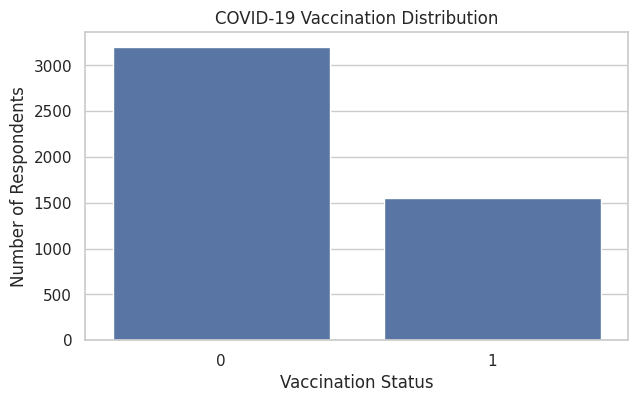

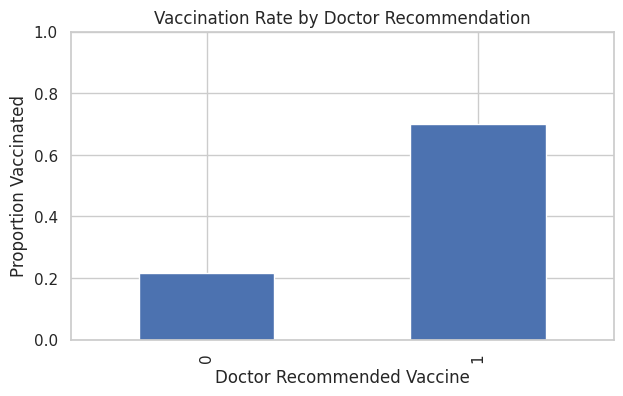

In [38]:

# Check missing percentages
missing = X.isnull().mean().mul(100)
print(missing.sort_values(ascending=False))

# Plot vaccination status
plt.figure(figsize=(7, 4))
sns.countplot(data=train, x="covid_vaccine")
plt.title("COVID-19 Vaccination Distribution")
plt.xlabel("Vaccination Status")
plt.ylabel("Number of Respondents")
plt.show()

# Doctor recommendation vs vaccination uptake
rates = train.groupby(
    "doctor_recc_covid"
)["covid_vaccine"].mean()

rates.plot(kind="bar", figsize=(7, 4))
plt.title("Vaccination Rate by Doctor Recommendation")
plt.ylabel("Proportion Vaccinated")
plt.xlabel("Doctor Recommended Vaccine")
plt.ylim(0, 1)
plt.show()


#Split training and validation data

In [39]:

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)


Training: (3804, 29)
Validation: (952, 29)


#Preprocess the features correctly

In [40]:
categorical_survey = [
    "covid_concern",
    "covid_knowledge",
    "behavioral_antiviral_meds",
    "behavioral_avoidance",
    "behavioral_face_mask",
    "behavioral_wash_hands",
    "behavioral_large_gatherings",
    "behavioral_outside_home",
    "behavioral_touch_face",
    "doctor_recc_covid",
    "child_under_6_months",
    "health_worker",
    "health_insurance",
    "opinion_covid_vacc_effective",
    "opinion_covid_risk",
    "opinion_covid_sick_from_vacc"
]

object_cols = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

categorical = sorted(
    set(object_cols + categorical_survey)
)

numerical = [
    c for c in X.columns
    if c not in categorical
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical),
    ("categorical", categorical_pipeline, categorical)
])

#Train five different models

In [41]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2500, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, random_state=42
    ),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, random_state=42
    )
}

# Force the ColumnTransformer to always return dense numpy arrays
if hasattr(preprocessor, "sparse_threshold"):
    preprocessor.sparse_threshold = 0

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predicted = pipeline.predict(X_valid)
    probabilities = pipeline.predict_proba(X_valid)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, predicted),
        "Precision": precision_score(y_valid, predicted),
        "Recall": recall_score(y_valid, predicted),
        "F1": f1_score(y_valid, predicted),
        "ROC_AUC": roc_auc_score(y_valid, probabilities)
    })

    trained_models[name] = pipeline

comparison = pd.DataFrame(results)
display(comparison.sort_values("ROC_AUC", ascending=False))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.810924,0.760956,0.614148,0.679715,0.833214
3,Gradient Boosting,0.802521,0.739300,0.610932,0.669014,0.829823
1,Random Forest,0.783613,0.733333,0.530547,0.615672,0.816966
2,Extra Trees,0.776261,0.711207,0.530547,0.607735,0.808737
4,Hist Gradient Boosting,0.779412,0.689139,0.591640,0.636678,0.805725


#Perform cross-validation and hyperparameter tuning

In [42]:

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2500,
        random_state=42
    ))
])

param_grid = {
    "model__C": [0.1, 1.0, 10.0]
}

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best mean CV ROC-AUC:", grid.best_score_)

best_logistic = grid.best_estimator_


Best parameters: {'model__C': 1.0}
Best mean CV ROC-AUC: 0.8361355407005594


# Calculate the assignment-specific financial metric

In [43]:

VACCINE_COST = 1500
HOSPITAL_COST = 41000
P_HOSP = 0.10  # Hypothetical assumption

def cost_per_person(y_true, predictions, p_h=P_HOSP):
    y_true = np.asarray(y_true)
    predictions = np.asarray(predictions)

    # Predicted 0 means offer vaccination
    offers = (predictions == 0).sum()

    # Actually unvaccinated, but predicted vaccinated
    missed = (
        (y_true == 0) & (predictions == 1)
    ).sum()

    total_cost = (
        offers * VACCINE_COST
        + missed * HOSPITAL_COST * p_h
    )

    return total_cost / len(y_true)


#Evaluate the best model

Accuracy: 0.7815126050420168
F1: 0.5574468085106383
ROC-AUC: 0.8332137787119201
              precision    recall  f1-score   support

           0       0.77      0.96      0.85       641
           1       0.82      0.42      0.56       311

    accuracy                           0.78       952
   macro avg       0.80      0.69      0.71       952
weighted avg       0.79      0.78      0.76       952

Cost per respondent: 1370.063025210084


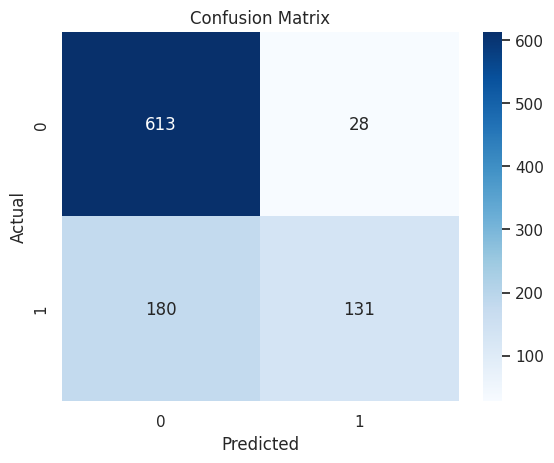

In [44]:

best_model = best_logistic

y_prob = best_model.predict_proba(X_valid)[:, 1]

# Use only if this threshold was chosen on training-only
# cross-validation, not the validation labels.
threshold = 0.65

y_pred = (y_prob >= threshold).astype(int)

print("Accuracy:", accuracy_score(y_valid, y_pred))
print("F1:", f1_score(y_valid, y_pred))
print("ROC-AUC:", roc_auc_score(y_valid, y_prob))
print(classification_report(y_valid, y_pred))

print(
    "Cost per respondent:",
    cost_per_person(y_valid, y_pred)
)

cm = confusion_matrix(y_valid, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


#Explainable AI (XAI)

,Feature,Importance
23,doctor_recc_covid,0.090997
25,opinion_covid_risk,0.054186
24,opinion_covid_vacc_effective,0.029136
10,health_worker,0.010585
27,employment_sector,0.009639
12,age_group,0.006972
13,education,0.003077
6,behavioral_large_gatherings,0.002790
15,sex,0.002115
14,race,0.001810


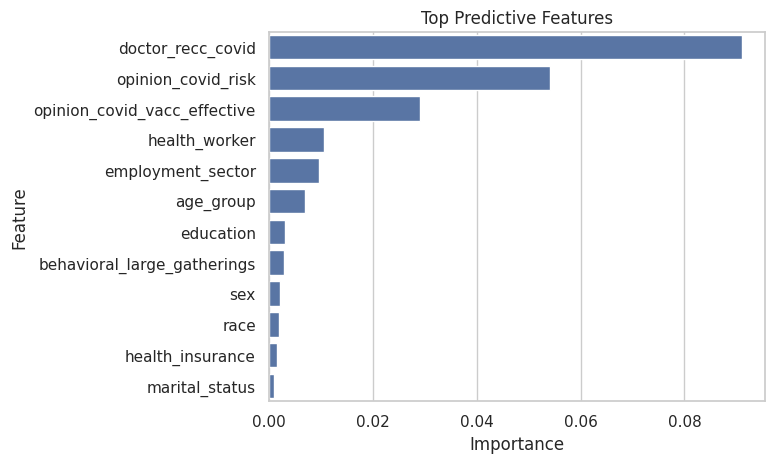

In [45]:

importance = permutation_importance(
    best_model,
    X_valid,
    y_valid,
    n_repeats=5,
    scoring="roc_auc",
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": X_valid.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

sns.barplot(
    data=feature_importance.head(12),
    x="Importance",
    y="Feature"
)
plt.title("Top Predictive Features")
plt.show()


#Predict covid_vaccine in the testing dataset

In [46]:

# Refit using the full labelled training dataset
best_model.fit(X, y)

# Predict probability of vaccination
test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

# Use training-only tuned threshold
threshold = 0.65

test_predictions = (
    test_probabilities >= threshold
).astype(int)

submission = pd.DataFrame({
    "respondent_id": test[ID].to_numpy(),
    "covid_vaccine": test_predictions
})

assert len(submission) == 4749
assert submission["covid_vaccine"].isin([0, 1]).all()

submission.to_csv(
    "dataset_C_final_predictions.csv",
    index=False
)

display(submission.head(10))
print(submission["covid_vaccine"].value_counts())


,respondent_id,covid_vaccine
0,4757,0
1,4758,0
2,4759,0
3,4760,0
4,4761,0
5,4762,1
6,4763,0
7,4764,1
8,4765,1
9,4766,0


covid_vaccine
0    3858
1     891
Name: count, dtype: int64


# target values

In [48]:

import pandas as pd

# Load your actual model results
results = pd.read_csv("model_comparison.csv")

TARGET_COST = 1500.00

results["saving_per_person"] = (
    TARGET_COST - results["validation_cost_per_person"]
)

results["meets_target"] = (
    results["validation_cost_per_person"] < TARGET_COST
)

results = results.sort_values(
    "validation_cost_per_person"
)

print("MODEL COST VALIDATION")
print(
    results[[
        "model",
        "validation_cost_per_person",
        "saving_per_person",
        "meets_target"
    ]].to_string(index=False)
)

best = results.iloc[0]

print("\nBEST MODEL:", best["model"])
print(
    "Estimated cost: $",
    round(best["validation_cost_per_person"], 2)
)
print(
    "Saving per respondent: $",
    round(best["saving_per_person"], 2)
)
print(
    "Meets $1,500 target:",
    bool(best["meets_target"])
)


MODEL COST VALIDATION
               model  validation_cost_per_person  saving_per_person  meets_target
  LogisticRegression                 1370.063025         129.936975          True
        RandomForest                 1373.319328         126.680672          True
HistGradientBoosting                 1374.054622         125.945378          True
          ExtraTrees                 1382.878151         117.121849          True
    GradientBoosting                 1385.294118         114.705882          True

BEST MODEL: LogisticRegression
Estimated cost: $ 1370.06
Saving per respondent: $ 129.94
Meets $1,500 target: True


#calculate the financial metric

In [49]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

VACCINE_COST = 1500
HOSPITAL_COST = 41000

def healthcare_cost(y_true, y_pred, hospitalisation_risk):

    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    if len(y_true) != len(y_pred) or len(y_true) == 0:
        raise ValueError("Invalid array lengths.")

    if not set(np.unique(y_true)).issubset({0, 1}):
        raise ValueError("Actual labels must be 0 or 1.")

    if not set(np.unique(y_pred)).issubset({0, 1}):
        raise ValueError("Predicted labels must be 0 or 1.")

    if not 0 <= hospitalisation_risk <= 1:
        raise ValueError("Risk must be between 0 and 1.")

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    # Illustrative policy:
    # Predicted 0 -> offer vaccination
    # Predicted 1 -> no vaccination offer

    # Correctly identified unvaccinated:
    # Offer vaccine
    cost_tn = tn * VACCINE_COST

    # Actually unvaccinated, predicted vaccinated:
    # Missed opportunity for vaccination
    cost_fp = (
        fp * hospitalisation_risk * HOSPITAL_COST
    )

    # Already vaccinated, predicted unvaccinated:
    # Unnecessary vaccination offer
    cost_fn = fn * VACCINE_COST

    # Already vaccinated, predicted vaccinated:
    # No additional intervention
    cost_tp = 0

    total_cost = (
        cost_tn + cost_fp + cost_fn + cost_tp
    )

    n = len(y_true)

    return {
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Cost_TN": cost_tn,
        "Cost_FP": cost_fp,
        "Cost_FN": cost_fn,
        "Cost_TP": cost_tp,
        "Total_Cost": total_cost,
        "Cost_Per_Respondent": total_cost / n
    }


# Fitted model and validation data from earlier steps
probabilities = best_model.predict_proba(X_valid)[:, 1]

# Example threshold — select properly on training CV
threshold = 0.65
predictions = (probabilities >= threshold).astype(int)

# Evaluate several assumed hospitalisation risks
risk_scenarios = [0.01, 0.03, 0.05, 0.10, 0.20]

results = []

for risk in risk_scenarios:

    metrics = healthcare_cost(
        y_valid,
        predictions,
        hospitalisation_risk=risk
    )

    results.append({
        "Risk": risk,
        **metrics
    })

cost_results = pd.DataFrame(results)

print("COST SENSITIVITY ANALYSIS")
display(cost_results.round(2))

print("\nCLASSIFICATION PERFORMANCE")

print("Accuracy:", accuracy_score(y_valid, predictions))
print("Precision:", precision_score(y_valid, predictions))
print("Recall:", recall_score(y_valid, predictions))
print("F1:", f1_score(y_valid, predictions))
print("ROC-AUC:", roc_auc_score(y_valid, probabilities))


COST SENSITIVITY ANALYSIS


,Risk,TN,FP,FN,TP,Cost_TN,Cost_FP,Cost_FN,Cost_TP,Total_Cost,Cost_Per_Respondent
0,0.01,615,26,180,131,922500,10660.0,270000,0,1203160.0,1263.82
1,0.03,615,26,180,131,922500,31980.0,270000,0,1224480.0,1286.22
2,0.05,615,26,180,131,922500,53300.0,270000,0,1245800.0,1308.61
3,0.10,615,26,180,131,922500,106600.0,270000,0,1299100.0,1364.60
4,0.20,615,26,180,131,922500,213200.0,270000,0,1405700.0,1476.58



CLASSIFICATION PERFORMANCE
Accuracy: 0.7836134453781513
Precision: 0.8343949044585988
Recall: 0.4212218649517685
F1: 0.5598290598290598
ROC-AUC: 0.8468129078860904


#Test whether  model really reduces costs

In [53]:
# Strategy 1: Offer vaccination to everyone
offer_everyone = np.zeros(len(y_valid), dtype=int)

# Strategy 2: Offer vaccination to nobody
offer_nobody = np.ones(len(y_valid), dtype=int)

# Strategy 3: Use the machine learning model
strategies = {
    "Offer everyone": offer_everyone,
    "Offer nobody": offer_nobody,
    "Machine learning model": predictions
}

rows = []

for name, pred in strategies.items():

    result = healthcare_cost(
        y_valid,
        pred,
        hospitalisation_risk=0.10
    )

    rows.append({
        "Strategy": name,
        "Cost per person": result["Cost_Per_Respondent"]
    })

comparison = pd.DataFrame(rows)

print(comparison.to_string(index=False))

              Strategy  Cost per person
        Offer everyone      1500.000000
          Offer nobody      2760.609244
Machine learning model      1364.600840
